#Surya Prasad M
#24BAD119

## Task A: Dataset Preparation

In [ ]:
# Roll No: 24BAD119
!pip install -q datasets

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
!wget -q https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt -O tinyshakespeare.txt

with open("tinyshakespeare.txt", "r", encoding="utf-8") as f:
    text = f.read()

print("Text length:", len(text))
print("\nFirst 2000 characters:\n")
print(text[:2000])

Text length: 1115394

First 2000 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in 

In [ ]:
# Convert text to lowercase
text = text.lower()

# Tokenize text into individual words
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts([text])

# Convert words to integer indices
word_sequences = tokenizer.texts_to_sequences([text])[0]

# Vocabulary size
vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)
print("\nFirst 30 numerical tokens:")
print(word_sequences[:30])

Vocabulary Size: 12634

First 30 numerical tokens:
[89, 270, 140, 36, 970, 144, 669, 128, 16, 103, 34, 103, 103, 89, 270, 7, 41, 34, 1269, 351, 4, 200, 64, 4, 3333, 34, 1269, 1269, 89, 270]


In [ ]:
# Generate input sequences for next-word prediction
sequence_length = 5
input_sequences = []

for i in range(sequence_length, len(word_sequences)):
    sequence = word_sequences[i-sequence_length:i+1]
    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

print("Input sequence shape:", input_sequences.shape)
print("\nExample sequence:", input_sequences[0])

# Show what the example means
print("\nInput words:")
print([tokenizer.index_word.get(i, "<UNK>") for i in input_sequences[0][:-1]])
print("Target word:")
print(tokenizer.index_word.get(input_sequences[0][-1], "<UNK>"))

Input sequence shape: (204084, 6)

Example sequence: [ 89 270 140  36 970 144]

Input words:
['first', 'citizen', 'before', 'we', 'proceed']
Target word:
any


In [ ]:
# Separate inputs (first 5 words) and targets (next word)
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (204084, 5)
y shape: (204084,)


In [ ]:
# Split into training and validation datasets
split = int(0.8 * len(X))

X_train = X[:split]
y_train = y[:split]

X_val = X[split:]
y_val = y[split:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)

Training samples: 163267
Validation samples: 40817
Training input shape: (163267, 5)
Validation input shape: (40817, 5)


## Task B: Implementing the RNN Model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# Create the RNN model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64
    ),
    SimpleRNN(128),
    Dense(vocab_size, activation="softmax")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Task C: RNN Model Training and Performance Evaluation

In [ ]:
# Train the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128
)

Epoch 1/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 129s 99ms/step - accuracy: 0.0391 - loss: 6.8418 - val_accuracy: 0.0495 - val_loss: 6.8836
Epoch 2/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 123s 96ms/step - accuracy: 0.0745 - loss: 6.1868 - val_accuracy: 0.0743 - val_loss: 6.7867
Epoch 3/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 138s 93ms/step - accuracy: 0.0891 - loss: 5.8451 - val_accuracy: 0.0767 - val_loss: 6.8450
Epoch 4/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 130s 102ms/step - accuracy: 0.0986 - loss: 5.5768 - val_accuracy: 0.0771 - val_loss: 6.9426
Epoch 5/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 143s 103ms/step - accuracy: 0.1072 - loss: 5.3419 - val_accuracy: 0.0771 - val_loss: 7.0483
Epoch 6/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 120s 94ms/step - accuracy: 0.1192 - loss: 5.1252 - val_accuracy: 0.0753 - val_loss: 7.1614
Epoch 7/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 142s 94ms/step - accuracy: 0.1344 - loss: 4.9203 - val_accuracy: 0.0748 - val_loss: 7.2723
Epoch 8/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 128s 101ms/step - accurac

In [ ]:
# Record training and validation loss/accuracy
train_loss, train_accuracy = model.evaluate(X_train, y_train, verbose=0)
val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)

print("Training Loss      :", train_loss)
print("Training Accuracy  :", train_accuracy)
print("Validation Loss    :", val_loss)
print("Validation Accuracy:", val_accuracy)

Training Loss      : 4.820485591888428
Training Accuracy  : 0.1515493094921112
Validation Loss    : 7.605405807495117
Validation Accuracy: 0.06837837398052216


In [ ]:
# Display performance for every epoch
print("Epoch | Train Loss | Val Loss | Train Accuracy | Val Accuracy")

for i in range(len(history.history["loss"])):
    print(
        f"{i+1:5d} | "
        f"{history.history['loss'][i]:10.4f} | "
        f"{history.history['val_loss'][i]:8.4f} | "
        f"{history.history['accuracy'][i]:14.4f} | "
        f"{history.history['val_accuracy'][i]:12.4f}"
    )

Epoch | Train Loss | Val Loss | Train Accuracy | Val Accuracy
    1 |     6.8418 |   6.8836 |         0.0391 |       0.0495
    2 |     6.1868 |   6.7867 |         0.0745 |       0.0743
    3 |     5.8451 |   6.8450 |         0.0891 |       0.0767
    4 |     5.5768 |   6.9426 |         0.0986 |       0.0771
    5 |     5.3419 |   7.0483 |         0.1072 |       0.0771
    6 |     5.1252 |   7.1614 |         0.1192 |       0.0753
    7 |     4.9203 |   7.2723 |         0.1344 |       0.0748
    8 |     4.7250 |   7.3826 |         0.1539 |       0.0728
    9 |     4.5413 |   7.4935 |         0.1757 |       0.0704
   10 |     4.3699 |   7.6054 |         0.1982 |       0.0684


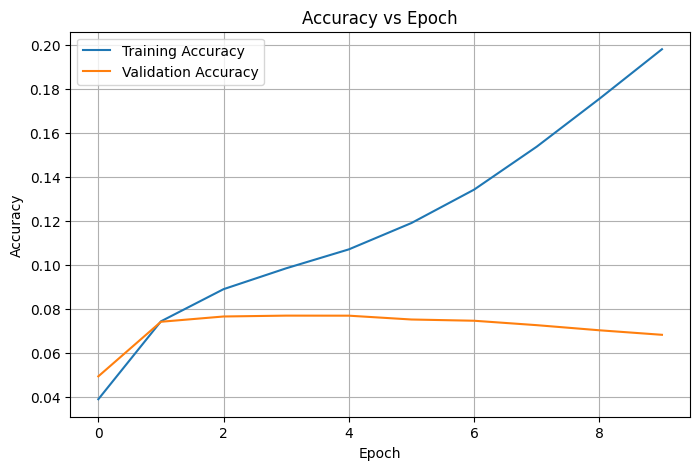

In [ ]:
# Accuracy vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

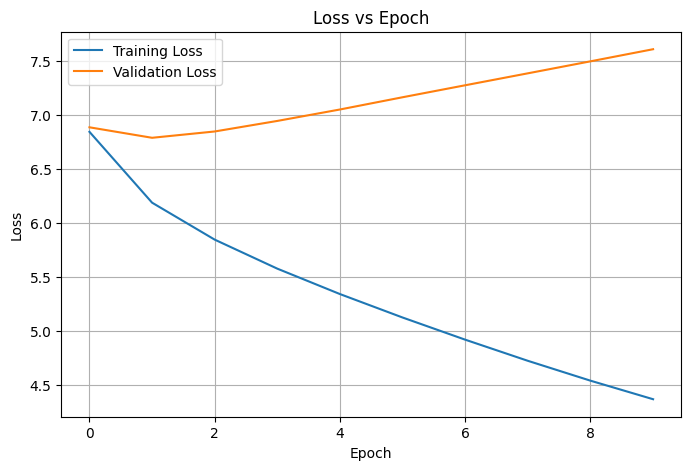

In [ ]:
# Loss vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

## Task D: Deep Learning Experiment Management

In [ ]:
# Function to generate text using the trained RNN

def generate_text(seed_text, next_words=20):
    generated_text = seed_text.lower()

    for _ in range(next_words):

        # Convert current text into integer tokens
        token_list = tokenizer.texts_to_sequences([generated_text])[0]

        # Keep only the last sequence_length tokens
        token_list = token_list[-sequence_length:]

        # Pad sequence to fixed length
        token_list = pad_sequences(
            [token_list],
            maxlen=sequence_length,
            padding="pre"
        )

        # Predict probabilities for the next word
        predicted_probabilities = model.predict(
            token_list,
            verbose=0
        )[0]

        # Select the word with highest probability
        predicted_id = np.argmax(predicted_probabilities)

        # Convert integer ID back to word
        output_word = tokenizer.index_word.get(predicted_id, "")

        if output_word == "":
            break

        generated_text += " " + output_word

    return generated_text

In [ ]:
# Generate multiple samples using different seed inputs

seeds = [
    "the king",
    "my lord",
    "i will",
    "to be",
    "what is"
]

for i, seed in enumerate(seeds, 1):
    print(f"Sample {i} - Seed: '{seed}'")
    print(generate_text(seed, next_words=20))
    print("-" * 80)

Sample 1 - Seed: 'the king'
the king of my heart and my poor sleep's disturbers is the queen and then i have heard the law of the
--------------------------------------------------------------------------------
Sample 2 - Seed: 'my lord'
my lord northumberland come my lord hastings and my lord king richard iii why then i am not coop'd on the innocent
--------------------------------------------------------------------------------
Sample 3 - Seed: 'i will'
i will not be a man of my poor sons and dispersed and scatter'd in the air of a kneeling point to
--------------------------------------------------------------------------------
Sample 4 - Seed: 'to be'
to be the duke of york i have not my heart is imprison'd to the rest and brought them to the king
--------------------------------------------------------------------------------
Sample 5 - Seed: 'what is'
what is the other of the field the gods have been abused to the wall that we may set me to the
-----------------------------------